In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

import cafein.sampledata.helsinki as helsinki
from cafein import TransportNetwork, TravelTimeMatrix

# The artifact saved in "Building a network"; build it there if it is missing.
network = TransportNetwork.load("../networks/helsinki-region.cafein")
departure = "2026-09-08 08:30"

In [2]:
origin_records = [
    ("kamppi", 24.9318, 60.1693),
    ("kallio", 24.9526, 60.1841),
    ("toolo", 24.9192, 60.1873),
]

origins = gpd.GeoDataFrame(
    origin_records,
    columns=["id", "longitude", "latitude"],
)

origin_points = gpd.points_from_xy(
    origins["longitude"],
    origins["latitude"],
)
origins = origins.set_geometry(origin_points, crs="EPSG:4326")
origins

,id,longitude,latitude,geometry
0,kamppi,24.9318,60.1693,POINT (24.9318 60.1693)
1,kallio,24.9526,60.1841,POINT (24.9526 60.1841)
2,toolo,24.9192,60.1873,POINT (24.9192 60.1873)


In [3]:
destination_records = [
    ("railway_station", 24.9414, 60.1719),
    ("pasila", 24.9337, 60.1991),
    ("aalto_university", 24.8281, 60.1848),
    ("kalasatama", 24.9780, 60.1870),
    ("munkkiniemi", 24.8755, 60.1987),
    ("arabianranta", 24.9806, 60.2067),
    ("lauttasaari", 24.8727, 60.1594),
    ("maunula", 24.9236, 60.2302),
    ("malmi", 25.0126, 60.2515),
]

destinations = gpd.GeoDataFrame(
    destination_records,
    columns=["id", "longitude", "latitude"],
)

destination_points = gpd.points_from_xy(
    destinations["longitude"],
    destinations["latitude"],
)
destinations = destinations.set_geometry(
    destination_points,
    crs="EPSG:4326",
)
destinations

,id,longitude,latitude,geometry
0,railway_station,24.9414,60.1719,POINT (24.9414 60.1719)
1,pasila,24.9337,60.1991,POINT (24.9337 60.1991)
2,aalto_university,24.8281,60.1848,POINT (24.8281 60.1848)
3,kalasatama,24.9780,60.1870,POINT (24.978 60.187)
4,munkkiniemi,24.8755,60.1987,POINT (24.8755 60.1987)
5,arabianranta,24.9806,60.2067,POINT (24.9806 60.2067)
6,lauttasaari,24.8727,60.1594,POINT (24.8727 60.1594)
7,maunula,24.9236,60.2302,POINT (24.9236 60.2302)
8,malmi,25.0126,60.2515,POINT (25.0126 60.2515)


In [4]:
matrix = TravelTimeMatrix(
    network,
    origins,
    destinations,
    departure,
)

matrix.head(10)

,from_id,to_id,travel_time
0,kamppi,railway_station,9
1,kamppi,pasila,17
2,kamppi,aalto_university,21
3,kamppi,kalasatama,17
4,kamppi,munkkiniemi,27
5,kamppi,arabianranta,29
6,kamppi,lauttasaari,17
7,kamppi,maunula,32
8,kamppi,malmi,31
9,kallio,railway_station,17


In [5]:
exact_matrix = TravelTimeMatrix(
    network,
    origins,
    destinations,
    departure,
    output_time_units="seconds",
)

exact_matrix.head(10)

,from_id,to_id,travel_time
0,kamppi,railway_station,554
1,kamppi,pasila,1002
2,kamppi,aalto_university,1241
3,kamppi,kalasatama,1002
4,kamppi,munkkiniemi,1602
5,kamppi,arabianranta,1758
6,kamppi,lauttasaari,1042
7,kamppi,maunula,1915
8,kamppi,malmi,1888
9,kallio,railway_station,1033


In [6]:
population_grid = gpd.read_file(helsinki.population_grid)
regional_origins = population_grid.rename(
    columns={"asukkaita": "population"}
)
regional_origins = regional_origins[
    ["id", "population", "geometry"]
].copy()

shopping_centres = gpd.read_file(
    helsinki.pois.shopping_centre
)
jumbo = shopping_centres.loc[
    shopping_centres["name"] == "Jumbo"
].copy()
jumbo["id"] = jumbo["osm_id"].astype(str)
jumbo = jumbo[["id", "name", "geometry"]]

print(f"Population cells: {len(regional_origins):,}")
print(f"Destination: {jumbo.iloc[0]['name']}")

Population cells: 5,825
Destination: Jumbo


In [7]:
regional_matrix = TravelTimeMatrix(
    network,
    regional_origins,
    jumbo,
    departure,
)

regional_matrix.head()

,from_id,to_id,travel_time
0,Vaestotietoruudukko_2025.1,5052826,126
1,Vaestotietoruudukko_2025.2,5052826,132
2,Vaestotietoruudukko_2025.3,5052826,103
3,Vaestotietoruudukko_2025.4,5052826,103
4,Vaestotietoruudukko_2025.5,5052826,132


In [8]:
regional_times = regional_matrix[
    ["from_id", "travel_time"]
]

regional_map = regional_origins.merge(
    regional_times,
    left_on="id",
    right_on="from_id",
    how="left",
)

regional_map[["id", "travel_time", "geometry"]].head()


,id,travel_time,geometry
0,Vaestotietoruudukko_2025.1,126,"POLYGON ((362054.365 6689582.191, 362061.946 6..."
1,Vaestotietoruudukko_2025.2,132,"POLYGON ((361940.674 6685834.568, 361948.252 6..."
2,Vaestotietoruudukko_2025.3,103,"POLYGON ((361887.631 6684085.685, 361895.208 6..."
3,Vaestotietoruudukko_2025.4,103,"POLYGON ((361880.054 6683835.845, 361887.631 6..."
4,Vaestotietoruudukko_2025.5,132,"POLYGON ((361849.748 6682836.473, 361857.325 6..."


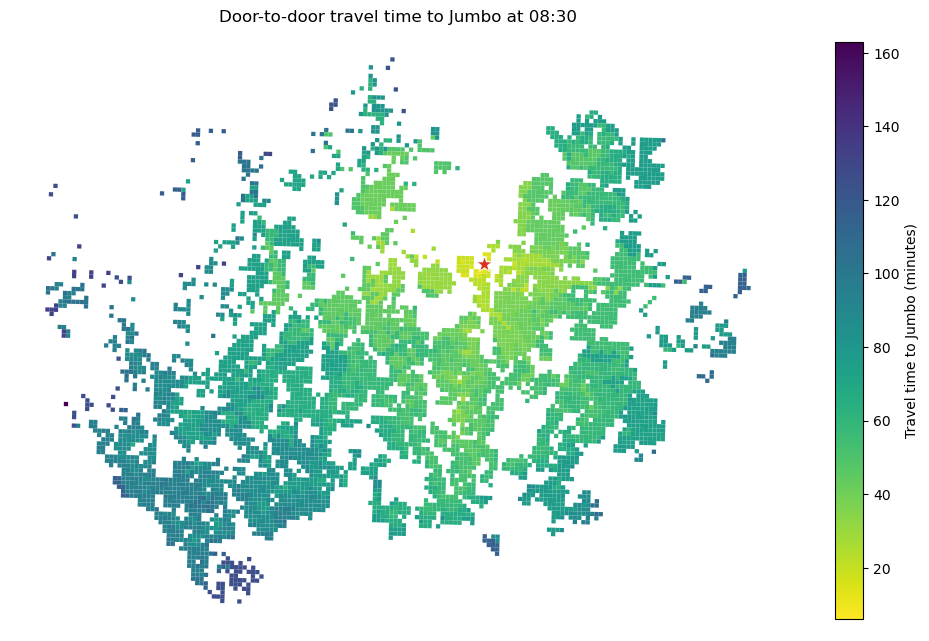

In [9]:
jumbo_for_map = jumbo.to_crs(regional_origins.crs)
jumbo_marker = jumbo_for_map.copy()
jumbo_marker["geometry"] = (
    jumbo_for_map.geometry.representative_point()
)

figure, axis = plt.subplots(figsize=(10, 8))

regional_map.plot(
    ax=axis,
    column="travel_time",
    cmap="viridis_r",
    linewidth=0,
    legend=True,
    legend_kwds={
        "label": "Travel time to Jumbo (minutes)",
        "shrink": 0.75,
    },
)

jumbo_marker.plot(
    ax=axis,
    marker="*",
    color="#d7301f",
    edgecolor="white",
    linewidth=0.7,
    markersize=150,
)

axis.set_title("Door-to-door travel time to Jumbo at 08:30")
axis.set_axis_off()
figure.tight_layout()

In [10]:
spread = TravelTimeMatrix(
    network,
    origins,
    destinations,
    departure,
    departure_time_window=30,
    confidence=0.9,
)

spread.head(10)

,from_id,to_id,travel_time_p5,travel_time_p50,travel_time_p95
0,kamppi,railway_station,8.0,9.0,10.0
1,kamppi,pasila,16.0,20.0,22.0
2,kamppi,aalto_university,19.0,20.0,21.0
3,kamppi,kalasatama,16.0,17.0,18.0
4,kamppi,munkkiniemi,25.0,28.0,32.0
5,kamppi,arabianranta,28.0,30.0,32.0
6,kamppi,lauttasaari,15.0,16.0,17.0
7,kamppi,maunula,32.0,38.0,41.0
8,kamppi,malmi,27.0,29.0,31.0
9,kallio,railway_station,15.0,16.0,17.0
